# Kardex: quality, exploratory analysis, and forecasting evidence
Re-executable from the repository root or `notebooks/`. No customer names are displayed. These are RUJAF-recorded outgoing sales, not confirmed Refama retail demand. Boundary months are unconfirmed and excluded from primary models. Full numerical conclusions: [final report](../reports/final_report.md).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from inventory_demand.config import Config
from inventory_demand.data import load_sources
from inventory_demand.cleaning import (clean_transactions, reconstruct_daily, monthly_datasets, reconcile_monthly, anonymize_transactions)
from inventory_demand.eda import run_eda
from inventory_demand.visualization import plot_eda
root = Path.cwd() if (Path.cwd() / 'kardex_csv').exists() else Path.cwd().parent
config = Config(root=root)
config.prepare()
sources, source_checks = load_sources(config)
transactions, quality = clean_transactions(sources['kardex_consolidado.csv'], config)
assert transactions.analysis_eligible.all(), 'Resolve invalid records before analysis'
display(source_checks)
display(quality[quality.flagged_rows > 0])

,file,source_rows,consolidated_rows,multiset_equal,only_individual,only_consolidated,same_product_order
0,kardex_90385-18025.csv,583,583,True,0,0,True
1,kardex_48815-14050.csv,479,479,True,0,0,True


,check,flagged_rows,action
13,missing_document,1,retain and investigate; no automatic deletion
14,extraction_flag,33,retain and investigate; no automatic deletion
16,text_encoding_issue,47,retain and investigate; no automatic deletion
18,repeated_business_candidate,12,retain and investigate; no automatic deletion
25,negative_balance,2,retain and investigate; no automatic deletion
26,zero_balance,10,retain and investigate; no automatic deletion
27,adjustment_requires_context,23,retain and investigate; no automatic deletion


## 1. Reconstruct calendar-month sales independently
Only `VENTA.salida` is sales. Purchases, production, adjustments, opening inventory, and returns remain distinct. Same-day PDF movement order determines closing inventory. A matching balance equation does not establish physical availability.

In [2]:
daily = reconstruct_daily(transactions, config)
monthly, coverage = monthly_datasets(transactions, daily)
reconciliation = reconcile_monthly(monthly, sources['ventas_mensuales_preliminares.csv'])
display(reconciliation.groupby('codigo_producto').matches_reference.agg(['size', 'sum']))
display(coverage[~coverage.complete_for_modeling])
display(anonymize_transactions(transactions).head(3))

,size,sum
codigo_producto,,
48815-14050,53,53
UAH-90385-18025,52,52


,codigo_producto,month,coverage_start,coverage_end,calendar_days,start_boundary,end_boundary,complete_for_modeling,coverage_status
0,48815-14050,2022-06-01,2022-06-02,2022-06-30,30,True,False,False,boundary_unconfirmed
52,48815-14050,2026-10-01,2026-10-01,2026-10-23,31,False,True,False,boundary_unconfirmed
53,UAH-90385-18025,2022-06-01,2022-06-02,2022-06-30,30,True,False,False,boundary_unconfirmed
104,UAH-90385-18025,2026-09-01,2026-09-01,2026-09-23,30,False,True,False,boundary_unconfirmed


,codigo_producto,descripcion_producto,fecha,fecha_pdf,tipo_movimiento,entrada,salida,saldo,venta_a_refama,pagina_pdf,...,implied_opening_balance,balance_error,balance_discrepancy,negative_balance,zero_balance,adjustment_net,adjustment_requires_context,monthly_sales_units,month,analysis_eligible
0,48815-14050,HULE BARRA ESTABILIZADORA TOYOTA HILUX 4x4 22....,2022-06-02,02/06/2022,COMPRA,199,0,199,NO,1,...,0.0,NaN,False,False,False,0,False,0,2022-06-01,True
1,48815-14050,HULE BARRA ESTABILIZADORA TOYOTA HILUX 4x4 22....,2022-06-03,03/06/2022,VENTA,0,10,189,NO,1,...,NaN,0.0,False,False,False,0,False,10,2022-06-01,True
2,48815-14050,HULE BARRA ESTABILIZADORA TOYOTA HILUX 4x4 22....,2022-06-08,08/06/2022,VENTA,0,24,165,NO,1,...,NaN,0.0,False,False,False,0,False,24,2022-06-01,True


## 2. Recompute exploratory tables and charts
Monthly moments exclude unconfirmed boundaries; all-observed totals retain them. Three scenarios are kept separate. All large orders and duplicate candidates are retained.

,codigo_producto,scenario,all_observed_sales_units,all_sales_transactions,complete_months,complete_sales_units,monthly_mean,monthly_median,monthly_std,monthly_cv,...,top_5_orders_share,top_10pct_orders_share,customer_count_raw_labels,top_customer_share,top_5_customers_share,customer_hhi_raw_labels,adi,cv2_positive_periods,zero_periods,demand_class
0,48815-14050,combined,6437,434,51,6188,121.333,105.0,58.702,0.484,...,0.047,0.251,179,0.161,0.375,0.047,1.000,0.234,0,smooth
1,48815-14050,other,4042,307,51,3829,75.078,70.0,50.233,0.669,...,0.074,0.290,168,0.085,0.247,0.021,1.041,0.390,2,smooth
2,48815-14050,refama,2395,127,51,2359,46.255,45.0,27.404,0.592,...,0.092,0.186,11,0.432,0.880,0.279,1.085,0.244,4,smooth
3,UAH-90385-18025,combined,66423,513,50,63938,1278.760,949.5,1186.111,0.928,...,0.090,0.517,230,0.050,0.215,0.020,1.000,0.860,0,erratic
4,UAH-90385-18025,other,62700,437,50,60515,1210.300,895.5,1174.112,0.970,...,0.096,0.500,220,0.053,0.228,0.021,1.000,0.941,0,erratic
5,UAH-90385-18025,refama,3723,76,50,3423,68.460,45.0,71.251,1.041,...,0.215,0.295,10,0.541,0.883,0.328,1.316,0.582,12,erratic


,codigo_producto,scenario,year,through_month,sales_units,yoy_growth
0,48815-14050,combined,2023,9,1188,NaN
1,48815-14050,combined,2024,9,1364,0.148148
2,48815-14050,combined,2025,9,1211,-0.112170
3,48815-14050,combined,2026,9,593,-0.510322
4,48815-14050,other,2023,9,813,NaN
5,48815-14050,other,2024,9,958,0.178352
6,48815-14050,other,2025,9,789,-0.176409
7,48815-14050,other,2026,9,251,-0.681876
8,48815-14050,refama,2023,9,375,NaN
9,48815-14050,refama,2024,9,406,0.082667


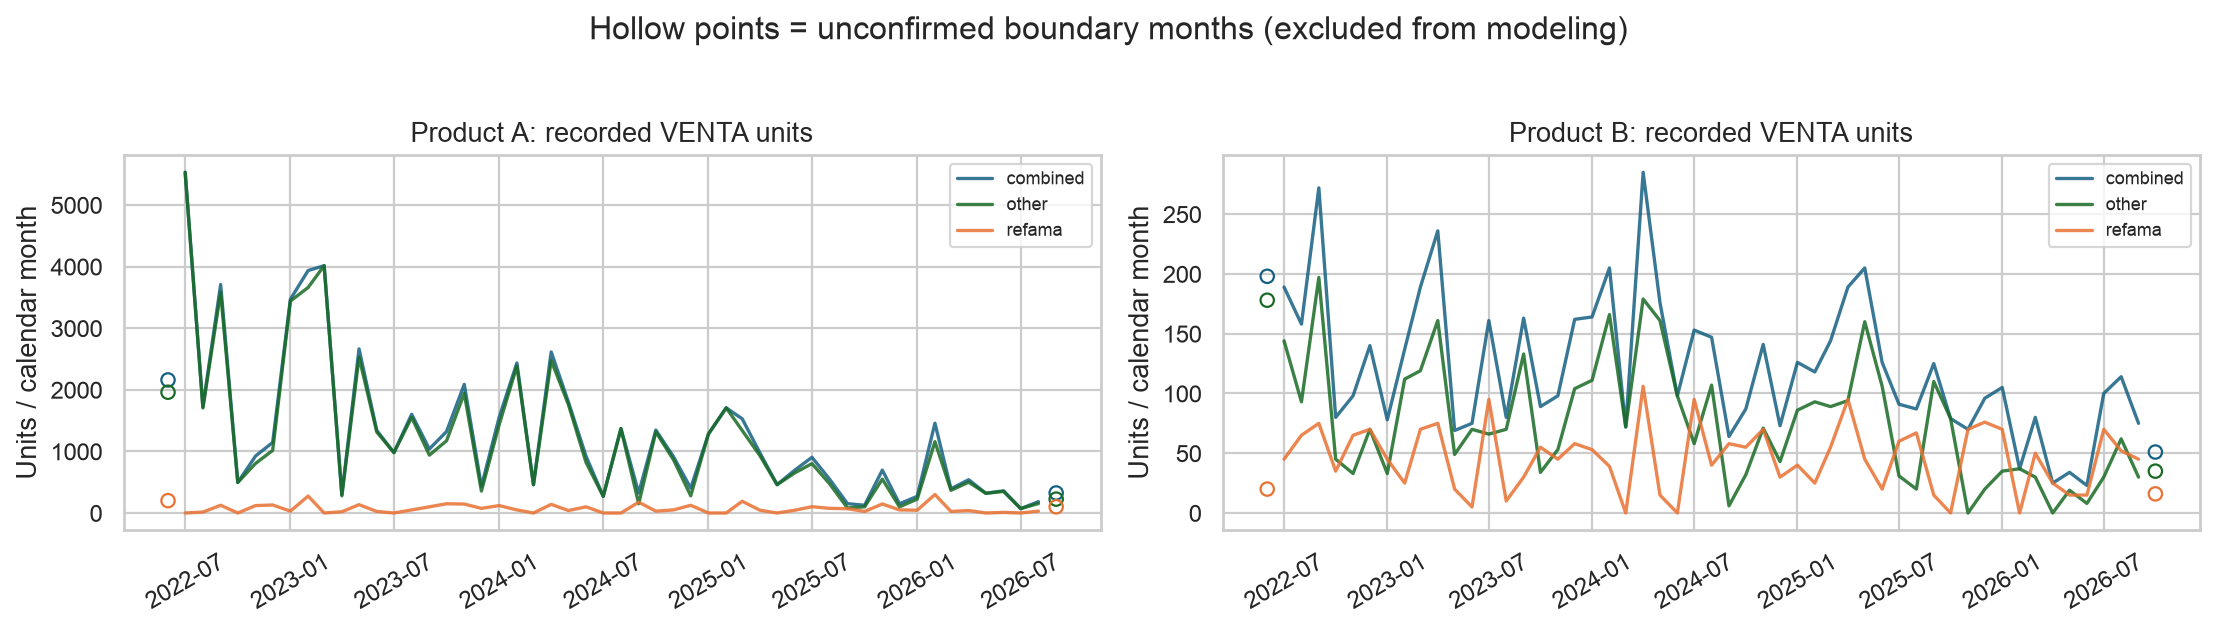

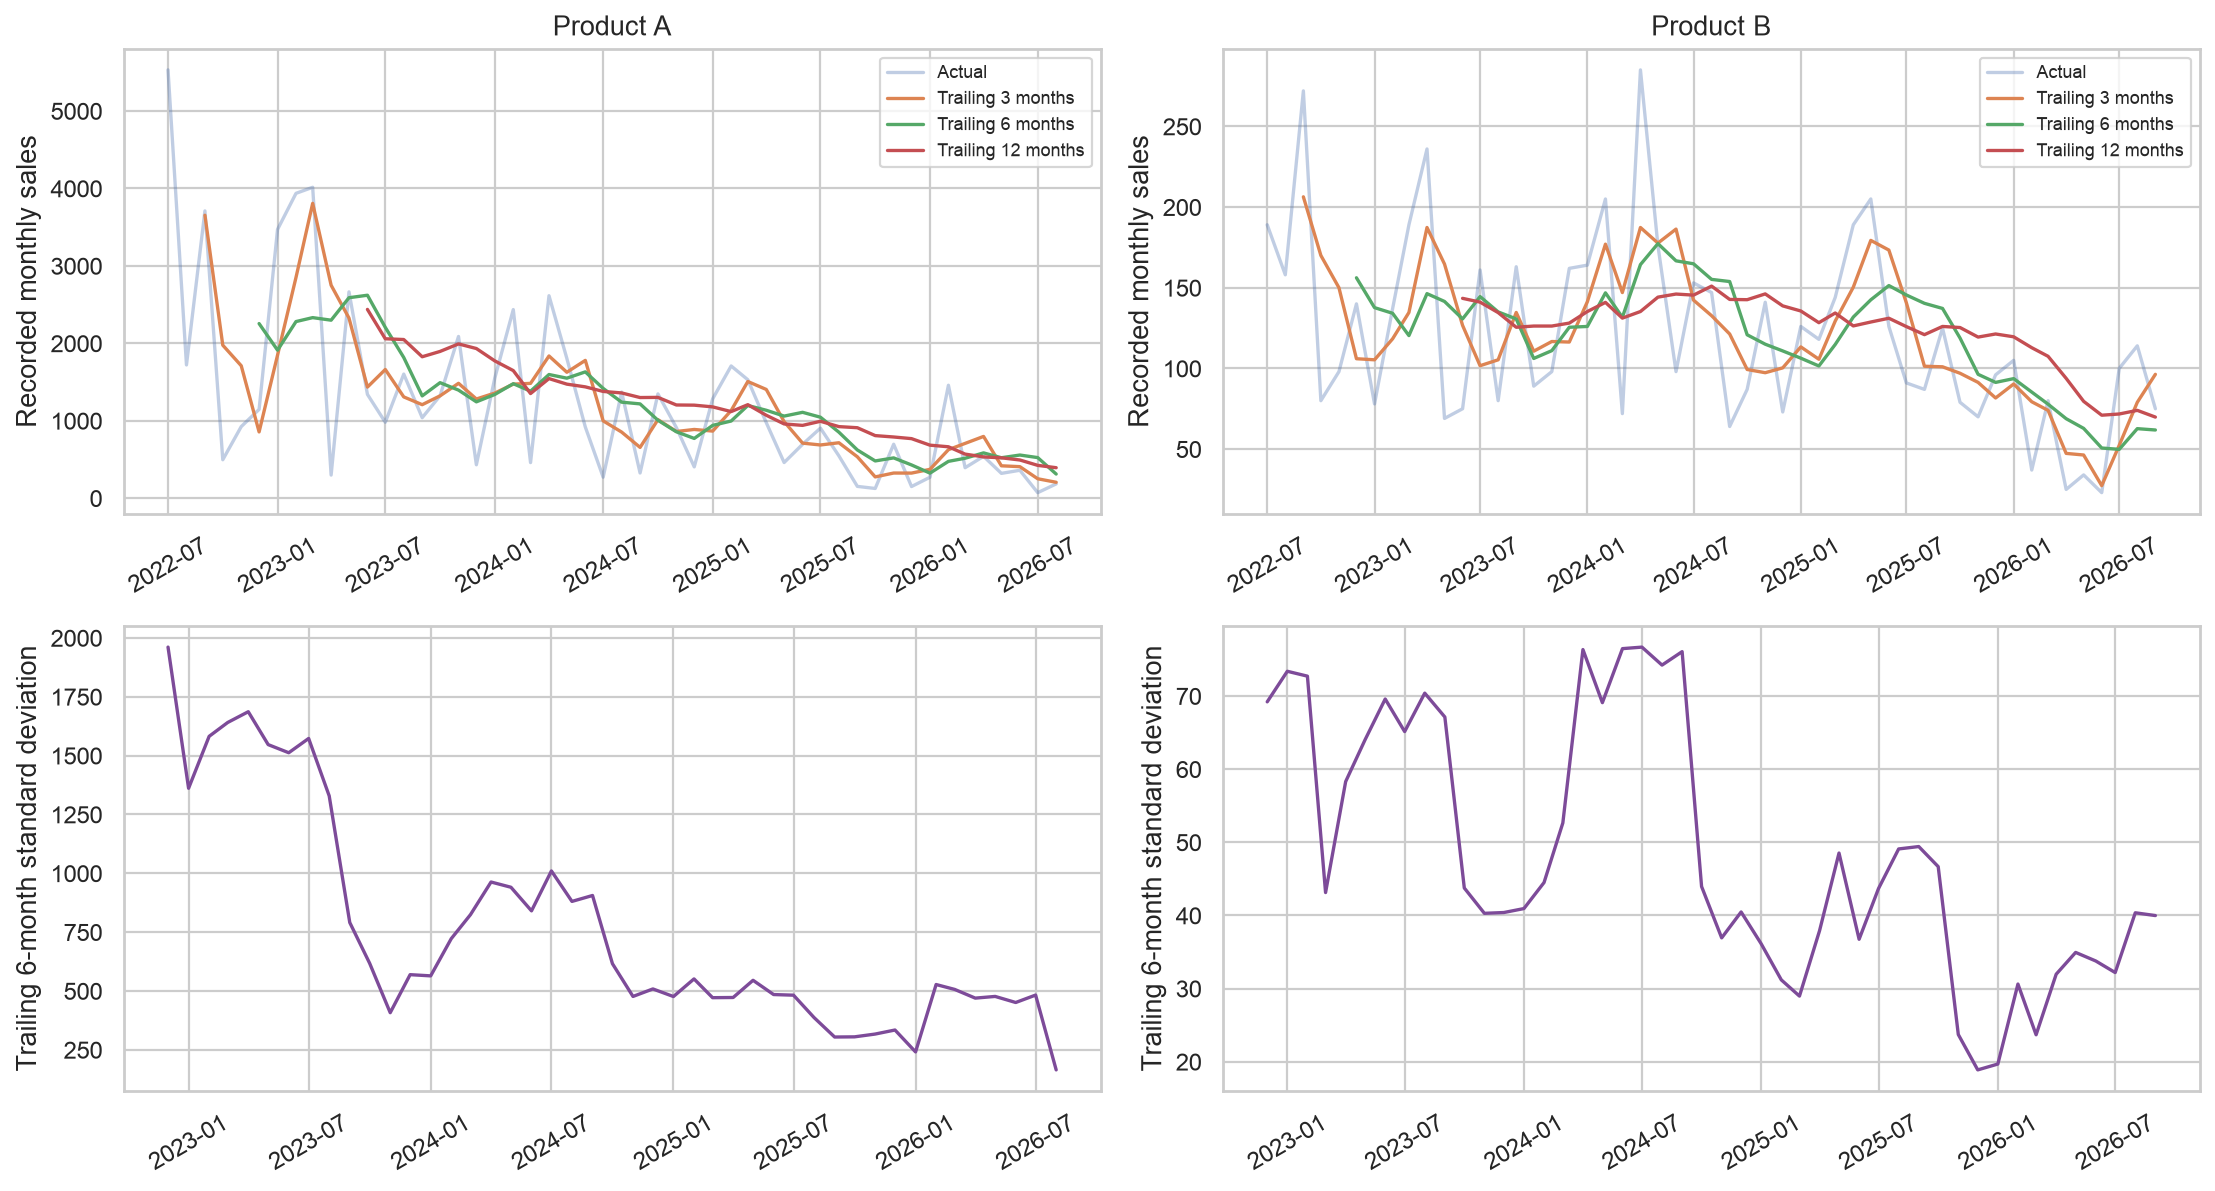

In [3]:
eda = run_eda(transactions, daily, monthly, config)
plot_eda(monthly, transactions, daily, eda, config)
display(eda['sales_summary'].round(3))
display(eda['comparable_ytd'])
display(Image(filename=str(config.figures / 'monthly_sales_scenarios.png')))
display(Image(filename=str(config.figures / 'rolling_trend_variability.png')))

## 3. Trend and seasonality: limited annual cycles
HAC trend/harmonic tests are exploratory; FDR adjusts six series. STL is descriptive, not proof of stable seasonality. ACF is computed on detrended log1p sales. Change points do not identify business causes.

,codigo_producto,scenario,months,log1p_slope,estimated_monthly_change,slope_ci_low,slope_ci_high,hac_slope_p,kendall_tau,kendall_p_unadjusted,first_12_mean,last_12_mean,last_12_vs_first_12,hac_slope_q_bh
0,48815-14050,combined,51,-0.0170,-0.0169,-0.0284,-0.0056,0.0034,-0.2901,0.0028,143.4167,69.8333,-0.5131,0.0050
1,48815-14050,other,51,-0.0339,-0.0333,-0.0538,-0.0141,0.0008,-0.3135,0.0012,93.8333,29.1667,-0.6892,0.0016
2,48815-14050,refama,51,-0.0104,-0.0103,-0.0244,0.0037,0.1478,-0.0793,0.4201,49.5833,40.6667,-0.1798,0.1774
3,UAH-90385-18025,combined,50,-0.0444,-0.0435,-0.0588,-0.0300,0.0000,-0.4688,0.0000,2437.2500,393.2500,-0.8387,0.0000
4,UAH-90385-18025,other,50,-0.0473,-0.0462,-0.0625,-0.0321,0.0000,-0.4622,0.0000,2364.3333,331.5000,-0.8598,0.0000
5,UAH-90385-18025,refama,50,-0.0024,-0.0024,-0.0399,0.0350,0.8986,-0.0601,0.5492,72.9167,61.7500,-0.1531,0.8986


,codigo_producto,scenario,annual_harmonic_hac_p,acf_lag_12,acf12_ci_low,acf12_ci_high,stl_seasonal_strength_descriptive,years_per_calendar_month_min,years_per_calendar_month_max,harmonic_q_bh,harmonic_evidence_after_fdr
0,48815-14050,combined,0.9256,-0.0959,-0.4064,0.2146,0.1729,4,5,0.9256,False
1,48815-14050,other,0.4273,-0.0999,-0.4018,0.2019,0.3471,4,5,0.5139,False
2,48815-14050,refama,0.4283,0.1177,-0.2049,0.4403,0.6266,4,5,0.5139,False
3,UAH-90385-18025,combined,0.0048,0.0518,-0.2493,0.3529,0.1289,4,5,0.0144,True
4,UAH-90385-18025,other,0.0021,0.1462,-0.1662,0.4587,0.1713,4,5,0.0127,True
5,UAH-90385-18025,refama,0.0147,0.0906,-0.2059,0.3870,0.0000,4,5,0.0295,True


,codigo_producto,scenario,candidate_change_month,max_split_statistic,block_bootstrap_p,before_mean_units,after_mean_units,interpretation,change_q_bh
0,48815-14050,combined,2025-10-01,1.821528,0.454545,137.179487,69.833333,"exploratory residual level shift, not a verifi...",0.903896
1,48815-14050,other,2025-10-01,1.866997,0.382617,89.205128,29.166667,"exploratory residual level shift, not a verifi...",0.903896
2,48815-14050,refama,2024-07-01,1.091849,0.753247,45.875000,46.592593,"exploratory residual level shift, not a verifi...",0.903896
3,UAH-90385-18025,combined,2025-09-01,1.262511,0.634366,1558.394737,393.250000,"exploratory residual level shift, not a verifi...",0.903896
4,UAH-90385-18025,other,2025-09-01,1.290008,0.632368,1487.815789,331.500000,"exploratory residual level shift, not a verifi...",0.903896
5,UAH-90385-18025,refama,2023-08-01,0.785882,0.968032,67.307692,68.864865,"exploratory residual level shift, not a verifi...",0.968032


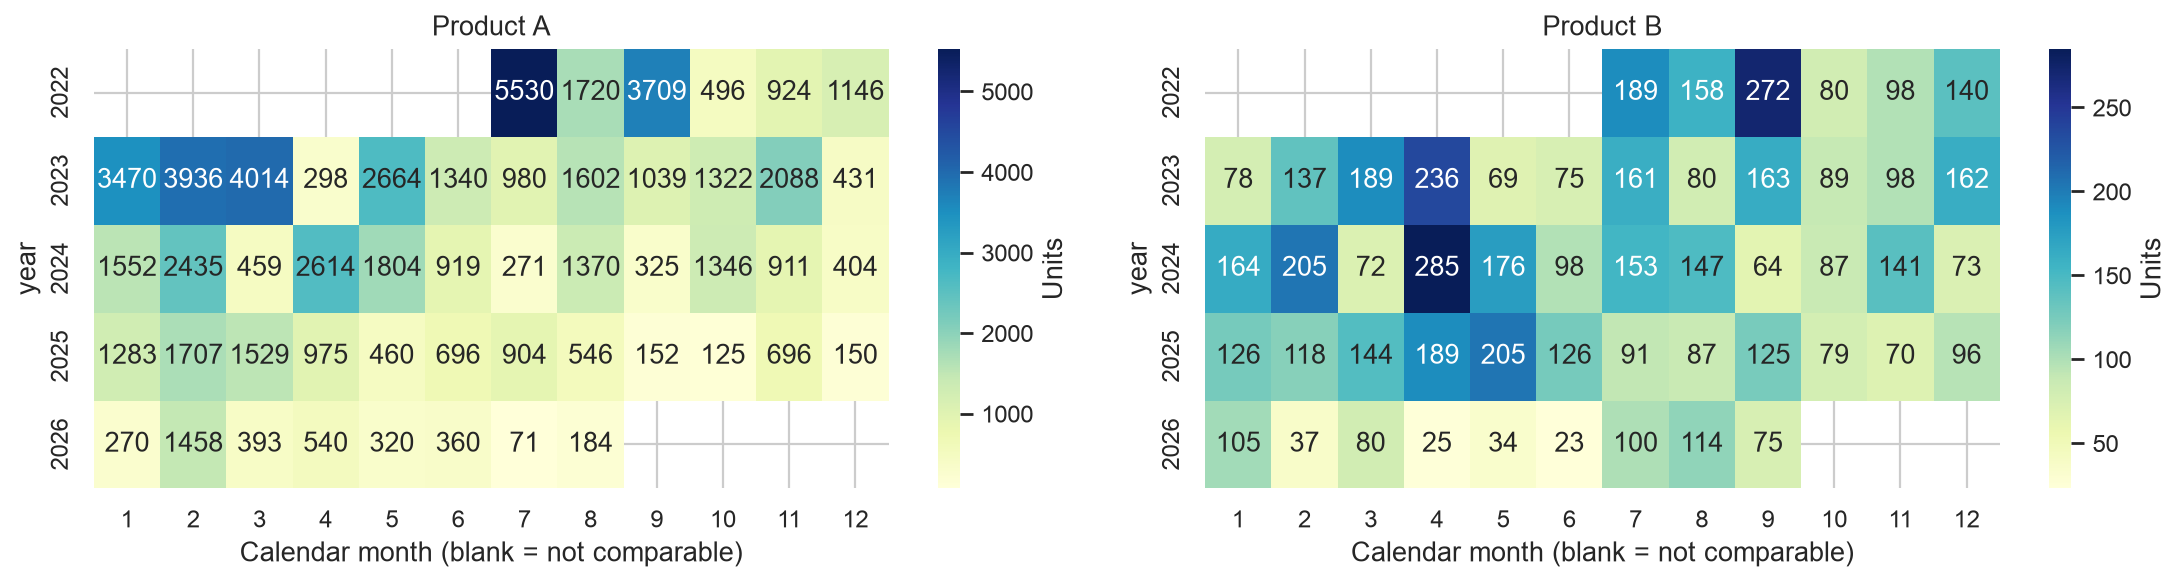

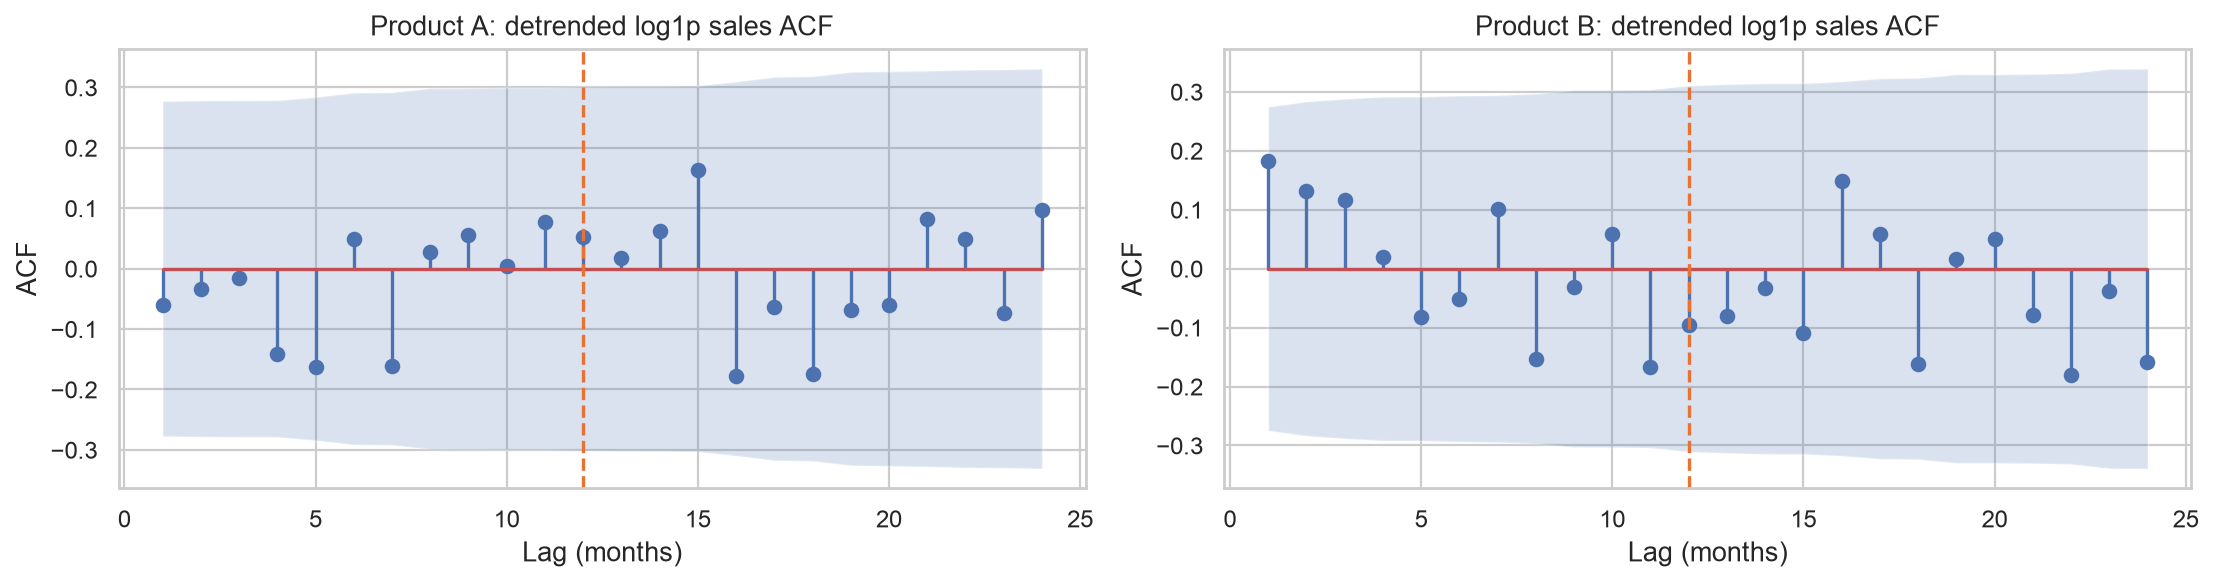

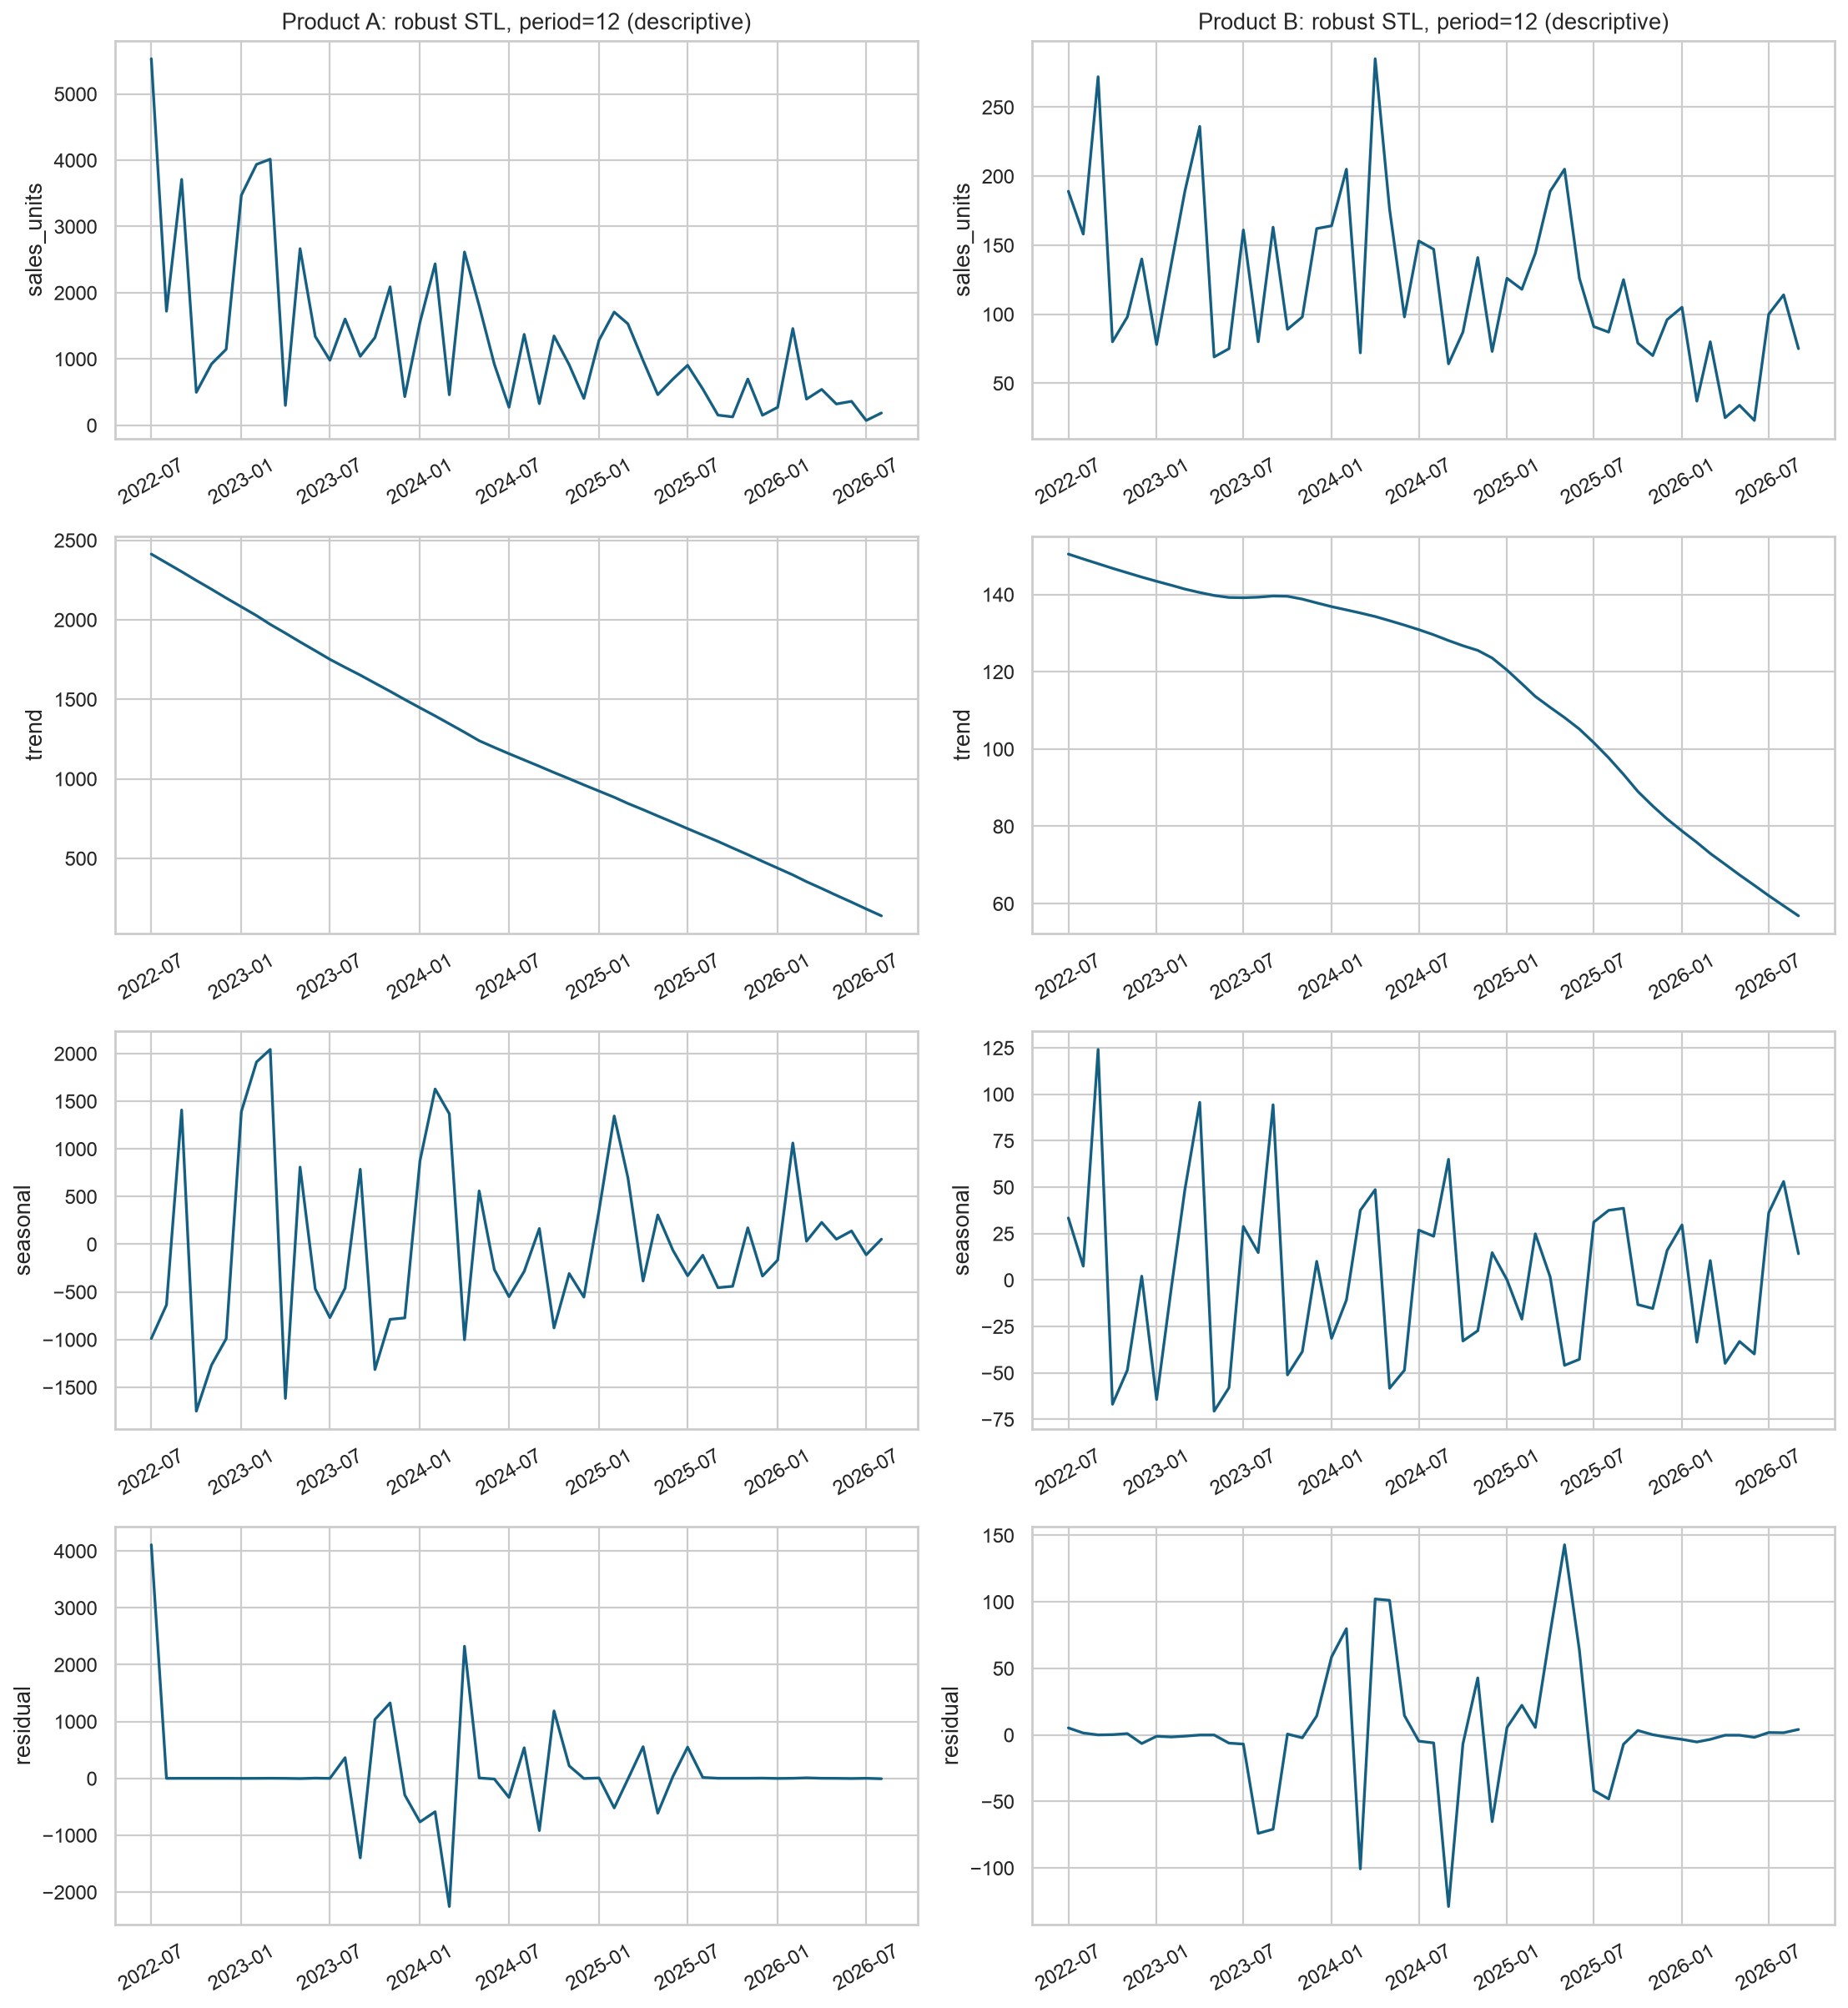

In [4]:
display(eda['trend'].round(4))
display(eda['seasonality'].round(4))
display(eda['change_points'])
display(Image(filename=str(config.figures / 'calendar_heatmap.png')))
display(Image(filename=str(config.figures / 'autocorrelation.png')))
display(Image(filename=str(config.figures / 'stl_decomposition.png')))

## 4. Inventory and anomalies
Zero/negative recorded balances can indicate availability constraints or accounting/timing issues. Forward-filled EOD stock is not a confirmed stockout duration or lost-sales estimate. Daily and monthly intermittency differ.

,codigo_producto,first_valid_date,last_valid_date,movements,ending_recorded_balance,minimum_recorded_balance,maximum_recorded_balance,negative_movement_balances,zero_movement_balances,eod_zero_days,...,eod_nonpositive_days,eod_low_stock_days,covered_days,carried_forward_days,observed_zero_event_days,longest_gap_without_movement_days,adjustment_incoming,adjustment_outgoing,opening_inventory_units,non_sale_outgoing
0,48815-14050,2022-06-02,2026-10-23,479,44,0,1244,0,5,8,...,8,65,1605,1250,3,25,536,299,199,299
1,UAH-90385-18025,2022-06-02,2026-09-23,583,5567,-206,14802,2,5,17,...,21,17,1575,1137,5,27,5246,5586,1879,5586


,codigo_producto,tipo_movimiento,is_opening_inventory,movements,incoming,outgoing,net
0,48815-14050,AJUSTE,False,16,536,299,237
1,48815-14050,COMPRA,False,2,825,0,825
2,48815-14050,COMPRA,True,1,199,0,199
3,48815-14050,PRODUCCION,False,26,5220,0,5220
4,48815-14050,VENTA,False,434,0,6437,-6437
5,UAH-90385-18025,AJUSTE,False,7,5246,5586,-340
6,UAH-90385-18025,COMPRA,False,25,20082,0,20082
7,UAH-90385-18025,COMPRA,True,1,1879,0,1879
8,UAH-90385-18025,DEVOLUCION C,False,1,15,0,15
9,UAH-90385-18025,PRODUCCION,False,36,50354,0,50354


,codigo_producto,aggregation,adi,cv2_positive_periods,zero_periods,demand_class
0,48815-14050,daily_interior_provisional,4.720365,0.673694,1224,lumpy
1,UAH-90385-18025,daily_interior_provisional,3.845960,2.686209,1127,lumpy


codigo_producto  type                          
48815-14050      document_or_repetition             8
                 large_adjustment                   2
                 large_sale                         1
UAH-90385-18025  abrupt_monthly_change_combined     3
                 abrupt_monthly_change_other        3
                 document_or_repetition             4
                 large_adjustment                   3
                 large_sale                        49
                 negative_balance                   2
Name: flags, dtype: int64

,codigo_producto,condition,start,end,days,observed_movements,sales_recorded_units,interpretation
2,48815-14050,eod_low_stock,2025-01-29,2025-03-04,35,14,138.0,recorded EOD balance / carry-forward; not conf...
5,48815-14050,eod_low_stock,2026-10-01,2026-10-15,15,1,20.0,recorded EOD balance / carry-forward; not conf...
7,UAH-90385-18025,eod_zero,2022-08-02,2022-08-15,14,6,105.0,recorded EOD balance / carry-forward; not conf...
11,UAH-90385-18025,eod_low_stock,2022-08-02,2022-08-15,14,6,105.0,recorded EOD balance / carry-forward; not conf...
4,48815-14050,eod_low_stock,2025-12-30,2026-01-07,9,3,31.0,recorded EOD balance / carry-forward; not conf...
0,48815-14050,eod_zero,2025-02-11,2025-02-18,8,10,112.0,recorded EOD balance / carry-forward; not conf...
1,48815-14050,eod_low_stock,2025-01-21,2025-01-23,3,1,30.0,recorded EOD balance / carry-forward; not conf...
3,48815-14050,eod_low_stock,2025-04-02,2025-04-04,3,4,35.0,recorded EOD balance / carry-forward; not conf...
6,UAH-90385-18025,eod_zero,2022-06-29,2022-07-01,3,4,200.0,recorded EOD balance / carry-forward; not conf...
9,UAH-90385-18025,eod_negative,2022-07-30,2022-08-01,3,1,1000.0,recorded EOD balance / carry-forward; not conf...


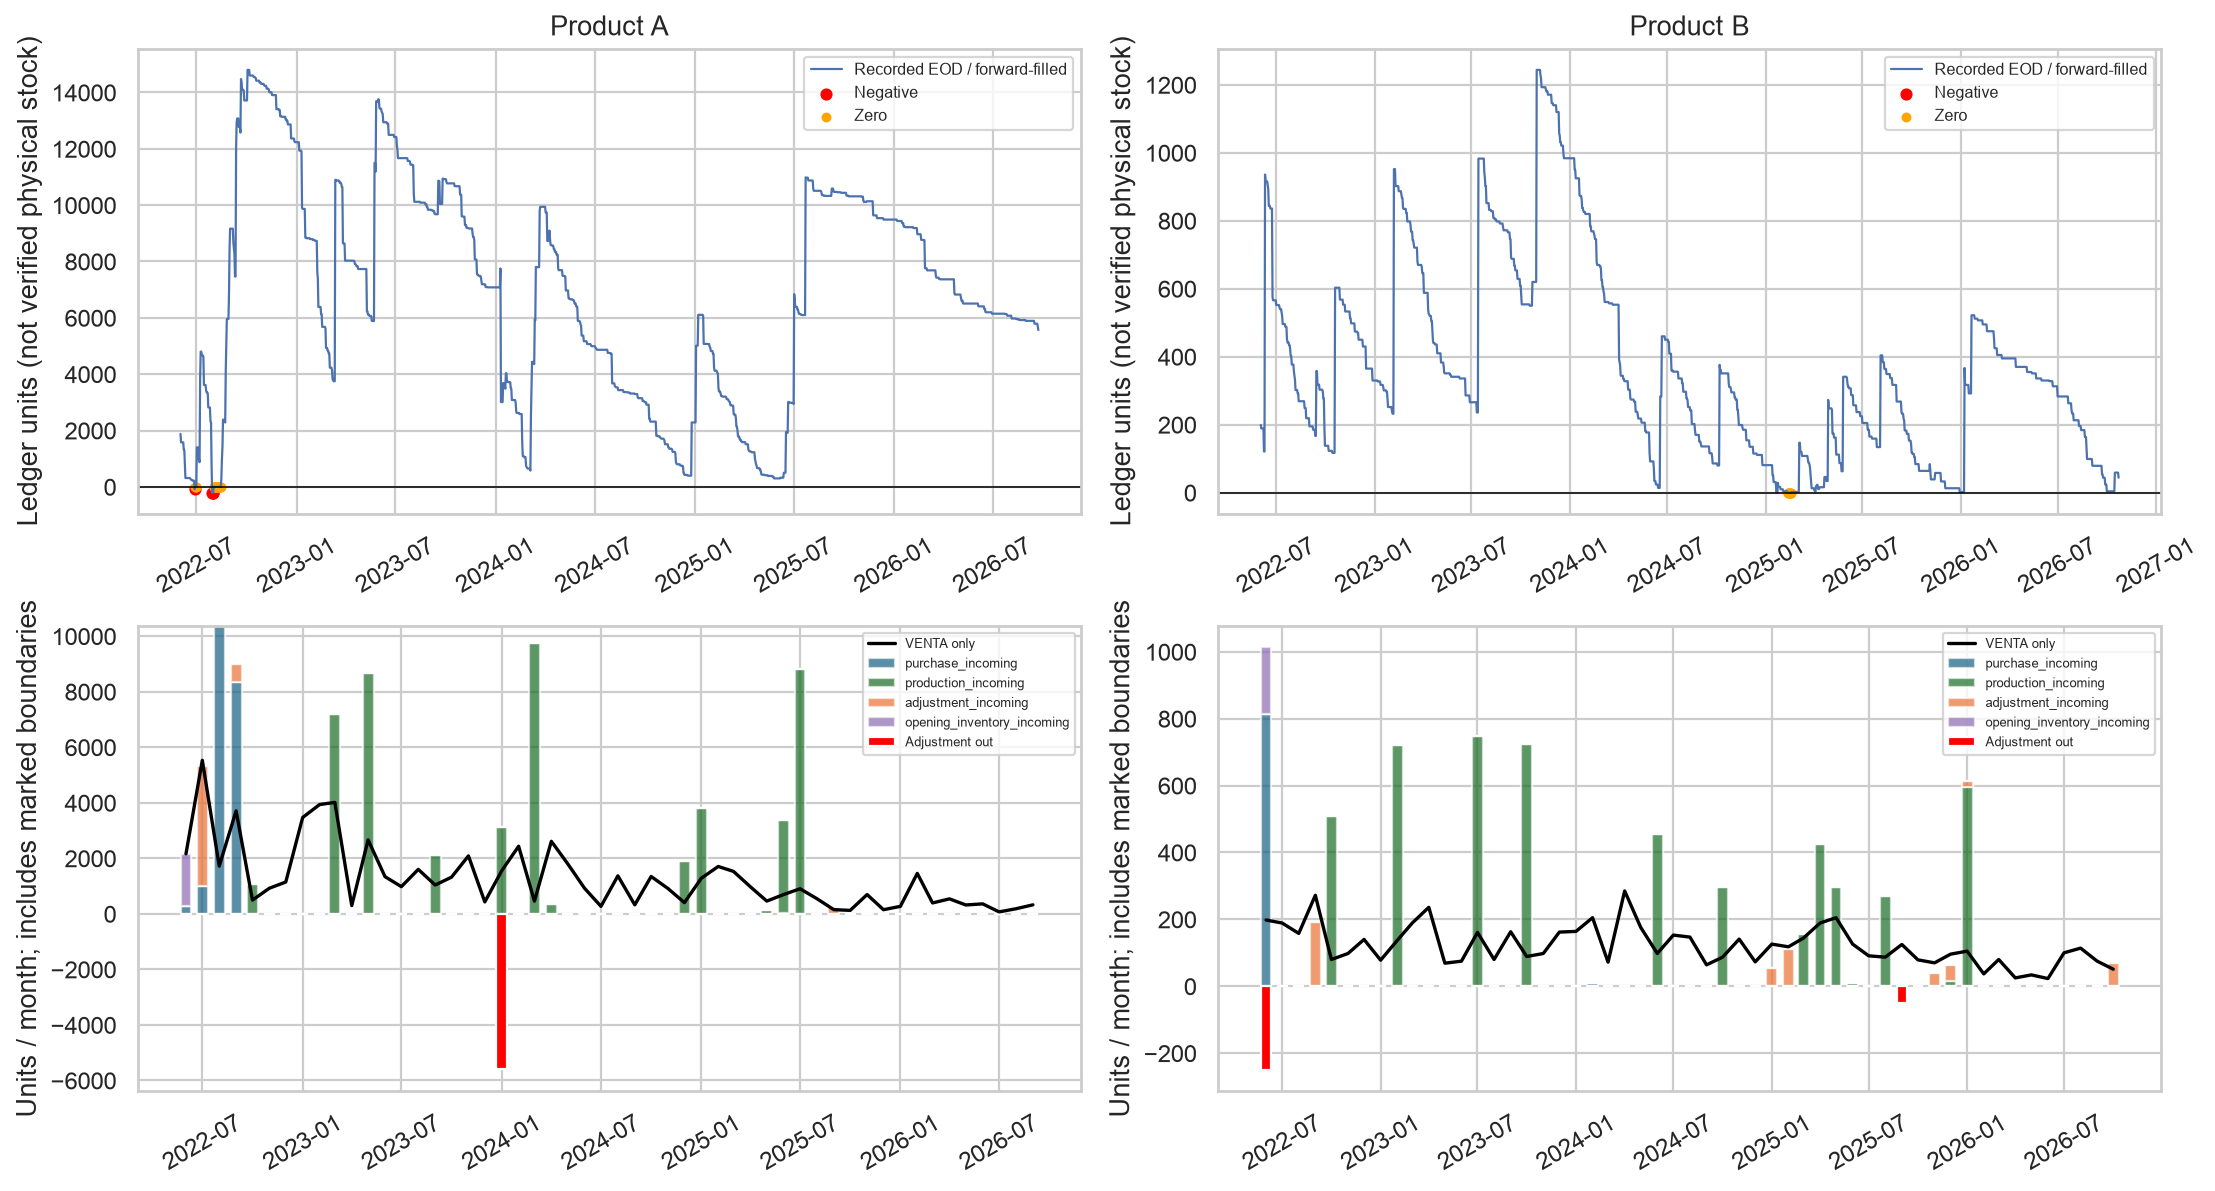

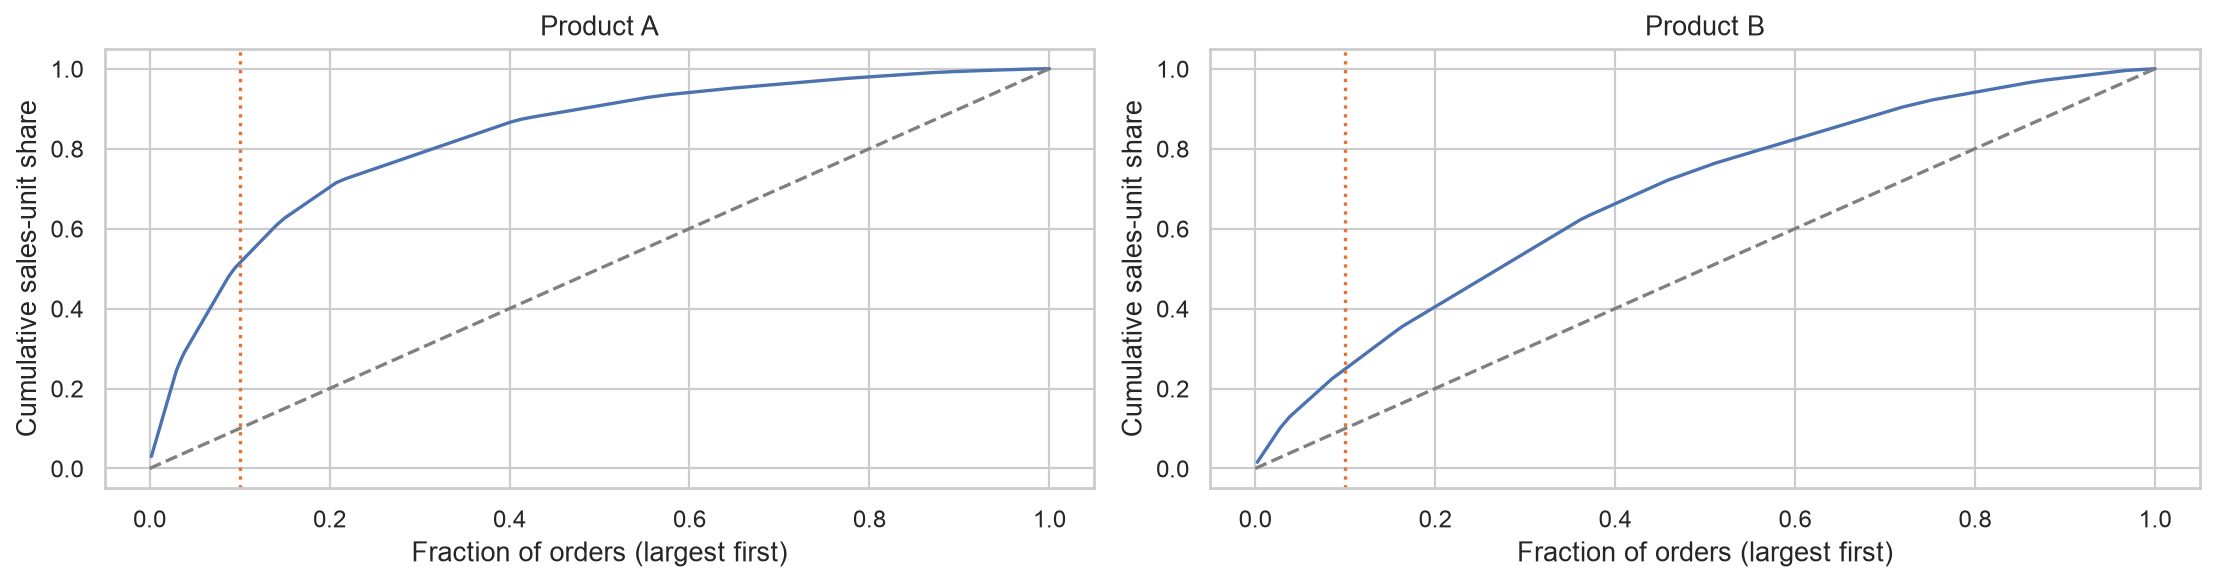

In [5]:
display(eda['inventory_summary'])
display(eda['movement_totals'])
display(eda['daily_intermittency'])
display(eda['anomalies'].groupby(['codigo_producto', 'type']).size().rename('flags'))
display(eda['recorded_low_stock_periods'].sort_values('days', ascending=False).head(10))
display(Image(filename=str(config.figures / 'inventory_and_supply.png')))
display(Image(filename=str(config.figures / 'order_concentration.png')))

## 5. Temporal forecasting outputs
Run `python scripts/run_pipeline.py` to regenerate all models. The final six complete months are held out after earlier expanding-origin selection. No random temporal split. These next-history-month forecasts are retrospective because report endpoints are unconfirmed; they are not live November forecasts. Inventory scenarios are explicitly hypothetical, and no actual financial savings are calculated.

,codigo_producto,scenario,model,best_raw_mae_model,selected_validation_mae,best_validation_mae,selection_rule,validation_start,validation_end,holdout_start,holdout_end,n_validation,n_holdout
0,48815-14050,combined,moving_average_3,ets_damped,34.952381,34.018646,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-03-01,2026-04-01,2026-09-01,21,6
1,48815-14050,other,naive,moving_average_3,37.714286,36.666667,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-03-01,2026-04-01,2026-09-01,21,6
2,48815-14050,refama,ets_seasonal_add,ets_seasonal_add,19.404788,19.404788,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-03-01,2026-04-01,2026-09-01,21,6
3,UAH-90385-18025,combined,ridge,linear_regression,380.648932,371.265644,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-02-01,2026-03-01,2026-08-01,20,6
4,UAH-90385-18025,other,ridge,ridge,370.308619,370.308619,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-02-01,2026-03-01,2026-08-01,20,6
5,UAH-90385-18025,refama,historical_average,ridge,60.206323,57.446976,simplest within 5% of lowest validation MAE; f...,2024-07-01,2026-02-01,2026-03-01,2026-08-01,20,6


,codigo_producto,scenario,phase,model,origins,successful_origins,all_origins_successful,clipped_origins,mae,rmse,wape,bias,bias_pct,mase,naive_mae,mae_skill_vs_naive,seasonal_naive_mae,mae_skill_vs_seasonal_naive
8,48815-14050,combined,holdout,naive,6,6,True,0,34.167,42.570,0.553,0.833,0.013,0.603,34.167,0.000,87.333,0.609
6,48815-14050,combined,holdout,moving_average_3,6,6,True,0,37.333,45.134,0.604,-7.444,-0.120,0.657,34.167,-0.093,87.333,0.573
7,48815-14050,combined,holdout,moving_average_6,6,6,True,0,42.222,45.267,0.683,0.278,0.004,0.741,34.167,-0.236,87.333,0.517
0,48815-14050,combined,holdout,ets_damped,6,6,True,0,42.649,49.178,0.690,24.359,0.394,0.744,34.167,-0.248,87.333,0.512
9,48815-14050,combined,holdout,random_forest,6,6,True,0,46.895,54.520,0.758,20.089,0.325,0.818,34.167,-0.373,87.333,0.463
1,48815-14050,combined,holdout,ets_level,6,6,True,0,47.356,53.260,0.766,20.081,0.325,0.827,34.167,-0.386,87.333,0.458
3,48815-14050,combined,holdout,gradient_boosting,6,6,True,0,51.313,58.262,0.830,25.973,0.420,0.895,34.167,-0.502,87.333,0.412
11,48815-14050,combined,holdout,sarima,6,6,True,0,59.140,72.968,0.956,54.631,0.884,1.030,34.167,-0.731,87.333,0.323
2,48815-14050,combined,holdout,ets_seasonal_add,6,6,True,0,62.963,85.849,1.018,22.285,0.360,1.098,34.167,-0.843,87.333,0.279
4,48815-14050,combined,holdout,historical_average,6,6,True,0,62.979,73.889,1.019,62.979,1.019,1.099,34.167,-0.843,87.333,0.279


,codigo_producto,scenario,model,forecast_origin,target_month,forecast_units,raw_forecast_units,nonnegative_clipped,model_warning,boundary_sales_exceed_point_forecast,lower80_heuristic,upper80_heuristic,lower95_heuristic,upper95_heuristic,units_already_in_unconfirmed_boundary,analysis_as_of,status,live_next_calendar_month,live_forecast_available
0,48815-14050,combined,moving_average_3,2026-09-30,2026-10-01,96.333333,96.333333,False,NaN,False,41.666667,151.000000,14.0,178.666667,51,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False
1,48815-14050,other,naive,2026-09-30,2026-10-01,30.000000,30.000000,False,NaN,True,0.000000,105.000000,0.0,131.000000,35,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False
2,48815-14050,refama,ets_seasonal_add,2026-09-30,2026-10-01,36.249953,36.249953,False,NaN,False,6.583279,65.916626,0.0,84.583291,16,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False
3,UAH-90385-18025,combined,ridge,2026-08-31,2026-09-01,0.000000,-102.294376,True,negative extrapolation clipped to zero; NOT ev...,True,0.000000,658.274291,0.0,951.845210,325,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False
4,UAH-90385-18025,other,ridge,2026-08-31,2026-09-01,0.000000,-163.597837,True,negative extrapolation clipped to zero; NOT ev...,True,0.000000,669.452935,0.0,1002.225550,225,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False
5,UAH-90385-18025,refama,historical_average,2026-08-31,2026-09-01,68.460000,68.460000,False,NaN,True,0.000000,145.335000,0.0,298.273953,100,2026-10-26,retrospective_boundary_forecast_NOT_live_next_...,2026-11-01,False


,codigo_producto,forecast_target_month,observed_balance_cutoff,observed_bookkeeping_balance,estimated_forecast_units,estimated_monthly_error_std,assumed_lead_time_months,assumed_service_level,assumed_on_order_units,assumed_backorders_units,assumed_review_months,status,inventory_position_units,reorder_point_units,order_up_to_units,reorder_trigger,suggested_order_units,warning
0,48815-14050,2026-10-01,2026-09-30,24.0,96.333333,41.445208,0.5,0.95,0,0,1,hypothetical_scenario,24.0,96.371056,227.992452,True,204,Retrospective hypothetical scenario; not a liv...
1,48815-14050,2026-10-01,2026-09-30,24.0,96.333333,41.445208,1.0,0.95,0,0,1,hypothetical_scenario,24.0,164.504635,289.075445,True,266,Retrospective hypothetical scenario; not a liv...
2,48815-14050,2026-10-01,2026-09-30,24.0,96.333333,41.445208,2.0,0.95,0,0,1,hypothetical_scenario,24.0,289.075445,407.076157,True,384,Retrospective hypothetical scenario; not a liv...
3,UAH-90385-18025,2026-09-01,2026-08-31,5892.0,0.000000,436.224477,0.5,0.95,0,0,1,hypothetical_scenario,5892.0,507.367085,878.785570,False,0,Retrospective hypothetical scenario; not a liv...
4,UAH-90385-18025,2026-09-01,2026-08-31,5892.0,0.000000,436.224477,1.0,0.95,0,0,1,hypothetical_scenario,5892.0,717.525413,1014.734171,False,0,Retrospective hypothetical scenario; not a liv...
5,UAH-90385-18025,2026-09-01,2026-08-31,5892.0,0.000000,436.224477,2.0,0.95,0,0,1,hypothetical_scenario,5892.0,1014.734171,1242.790471,False,0,Retrospective hypothetical scenario; not a liv...


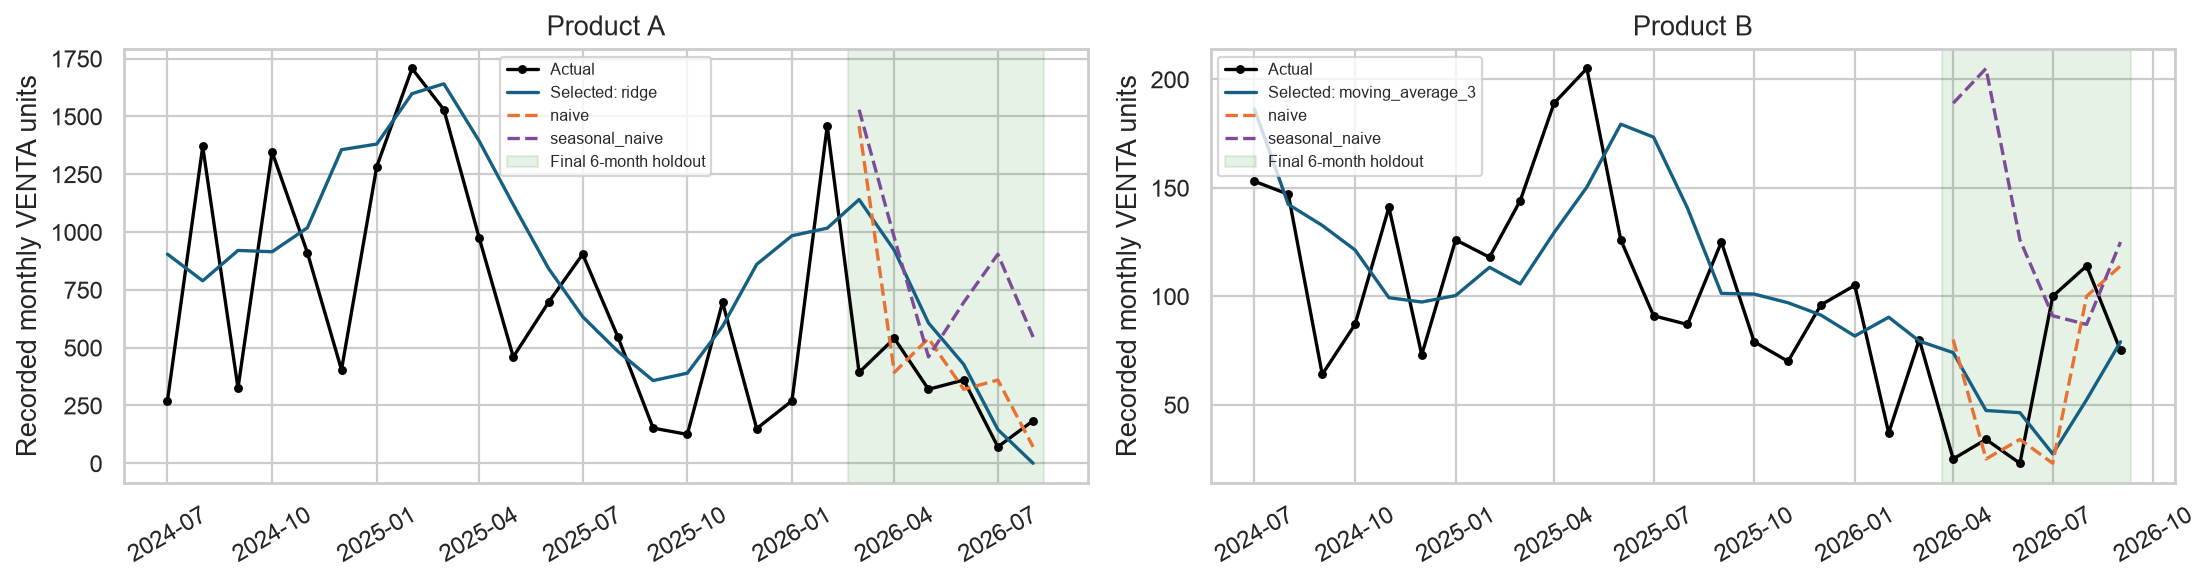

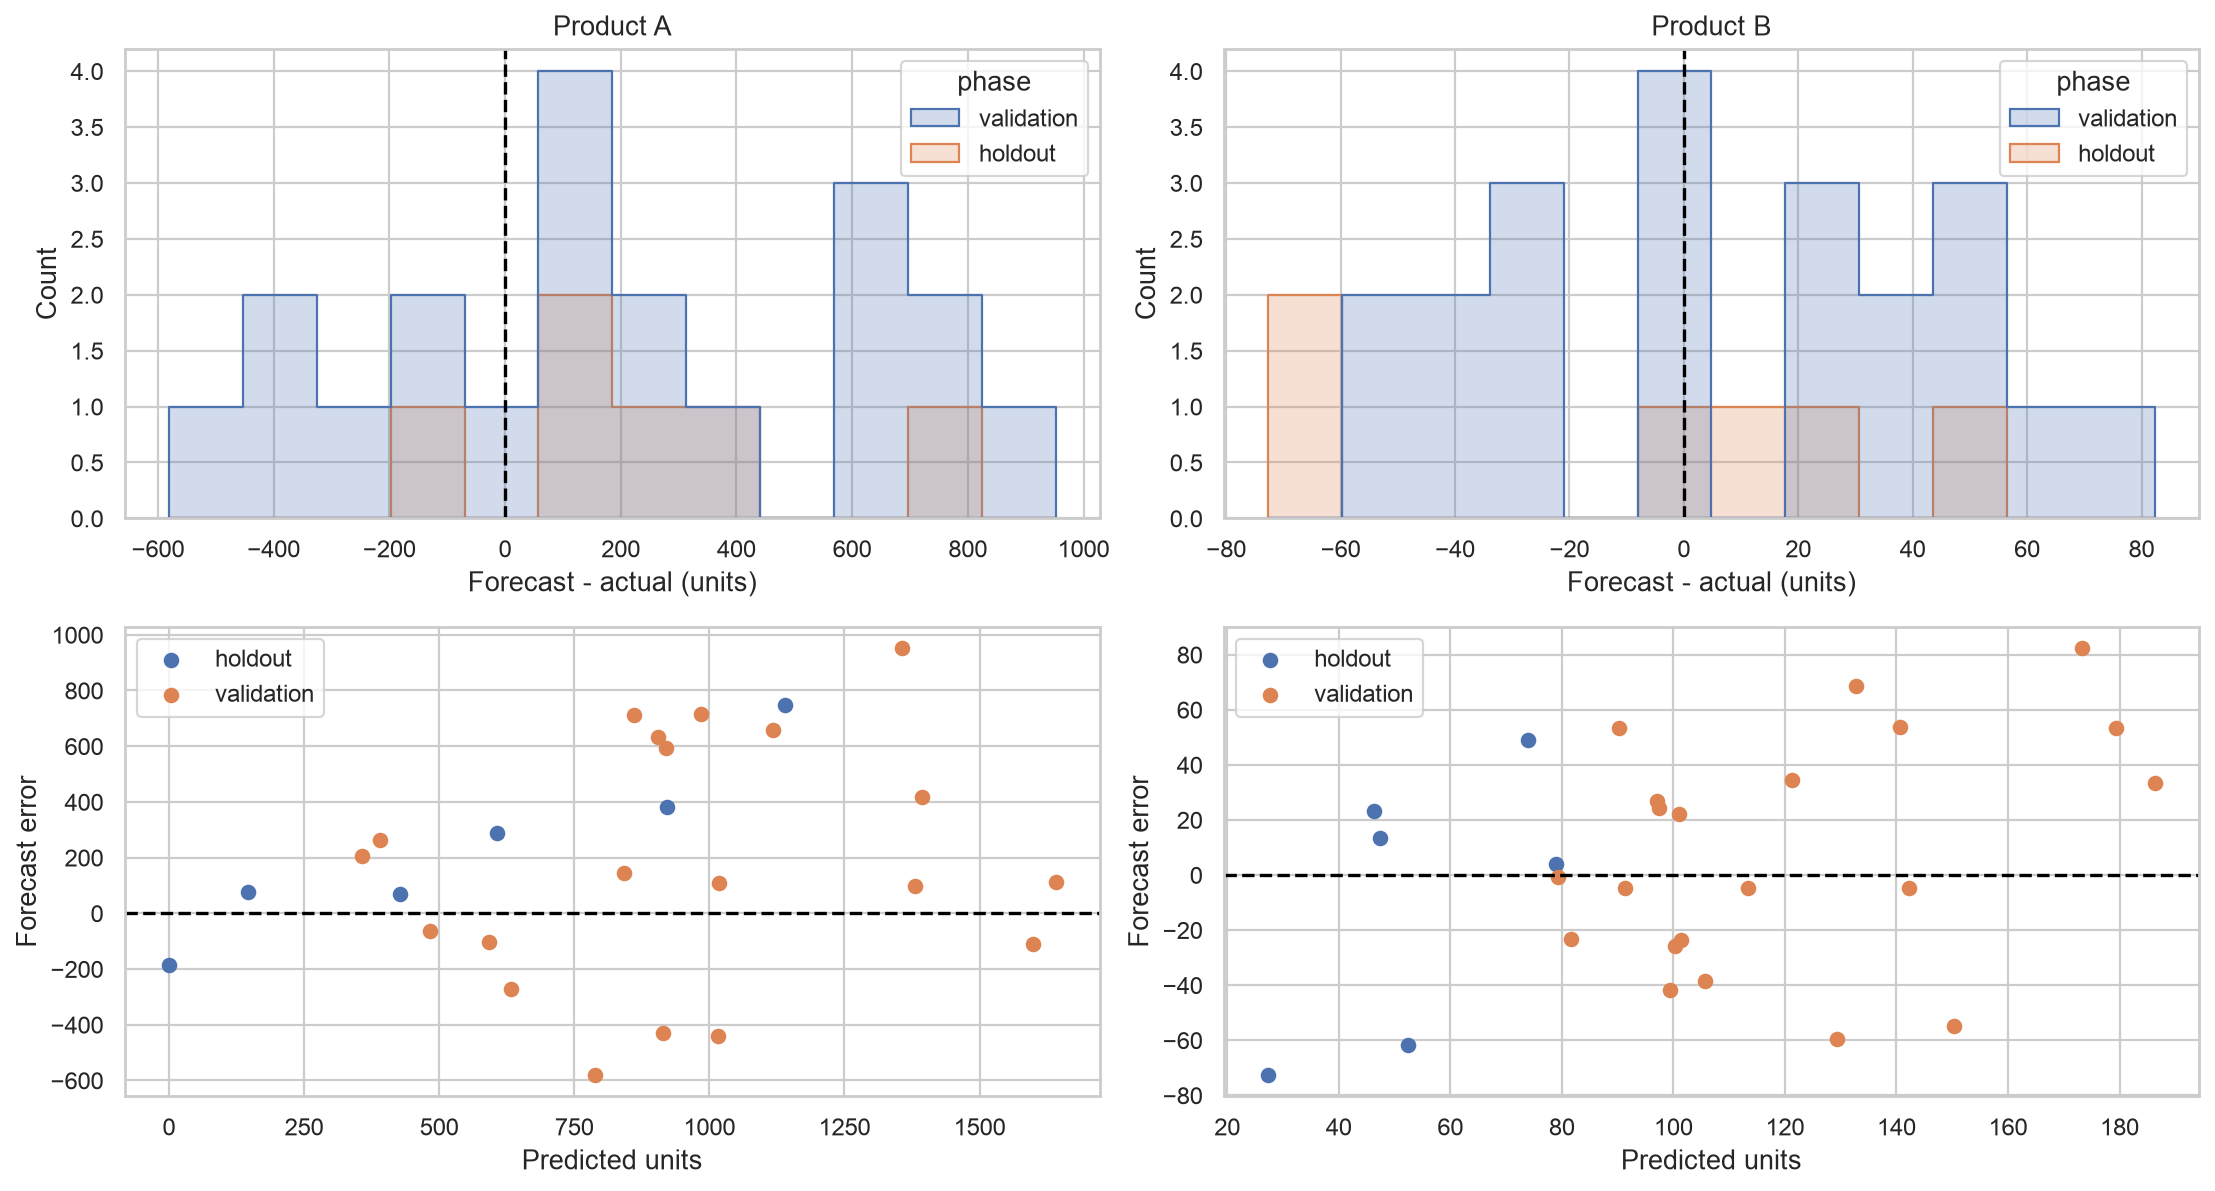

In [6]:
comparison_path = config.tables / 'model_comparison.csv'
if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    display(pd.read_csv(config.tables / 'selected_models.csv'))
    display(comparison[(comparison.scenario == 'combined') & (comparison.phase == 'holdout')].sort_values(['codigo_producto', 'mae']).round(3))
    display(pd.read_csv(config.tables / 'next_history_month_forecasts.csv'))
    display(pd.read_csv(config.tables / 'inventory_scenarios.csv'))
    display(Image(filename=str(config.figures / 'actual_vs_predicted.png')))
    display(Image(filename=str(config.figures / 'residual_analysis.png')))
else:
    print('Model outputs not yet present. Run the full pipeline; EDA above is independent.')